# PBL Fase 6 — O Começo da Rede Neural: Visão Computacional com YOLO

**Aluno:** Kaique Savi  |  **RM:** 562072  |  **Fase:** 6  |  **Cliente fictício:** FarmTech Solutions

A FarmTech Solutions está expandindo seus serviços de IA para a visão
computacional. Este notebook é a demonstração prática levada a um cliente que quer
entender **como funciona, na prática, um sistema que reconhece objetos em
imagens** — e o quanto dá para confiar nele.

O trabalho cobre as duas entregas obrigatórias da fase:

**Entrega 1 — YOLO customizado**

1. Organização do dataset (80 imagens, 2 classes, treino/validação/teste) no Google Drive.
2. Rotulação no [Make Sense AI](https://www.makesense.ai/) e conferência dos rótulos.
3. Treinamento do YOLOv5 em **duas simulações** com quantidades de épocas bem diferentes.
4. Validação, teste e comparação de acurácia, erro e desempenho.
5. Imagens de teste processadas pelo modelo.

**Entrega 2 — Abordagens concorrentes**

6. YOLO padrão (pré-treinado no COCO, sem customização).
7. CNN treinada do zero para classificar a imagem.
8. Comparação crítica: facilidade de uso, precisão, tempo de treino e tempo de inferência.

> **Como ler este notebook:** cada etapa tem uma célula de texto explicando *o que*
> será feito e *por quê*, seguida do código. As conclusões numéricas são geradas a
> partir dos resultados da própria execução, para que texto e números nunca
> fiquem dessincronizados.

---
# Entrega 1 — YOLO customizado

## 1. O dataset e sua organização no Google Drive

Escolhemos dois objetos bem diferentes entre si e ligados às novas frentes da
FarmTech:

- **Vaca** — saúde e monitoramento animal.
- **Capacete** — segurança e controle de acesso de funcionários (uso de EPI).

A escolha também é proposital para a Entrega 2: "vaca" existe entre as classes do
YOLO padrão, "capacete" não.

As imagens vêm do [Open Images Dataset V7](https://storage.googleapis.com/openimages/web/index.html)
(conjunto de validação), fotos reais publicadas sob licença **CC BY 2.0**. O
arquivo `dataset/creditos_imagens.csv` do repositório lista autor, link original
e licença de cada uma. Descartamos manualmente as imagens em que o objeto era
ambíguo (por exemplo, uma máscara de gás anotada como capacete).

São **40 imagens de cada classe**, divididas conforme o enunciado:

| Conjunto | Por classe | Total | Para que serve |
|----------|-----------:|------:|----------------|
| Treino | 32 | 64 | A rede ajusta seus pesos olhando para estas imagens. |
| Validação | 4 | 8 | Medida ao fim de cada época; escolhe o melhor peso (`best.pt`). |
| Teste | 4 | 8 | Nunca vistas no treino; simulam o uso real do modelo. |

As imagens ficam no Google Drive (com uma cópia na pasta `dataset/` do
repositório) na estrutura que o YOLOv5 espera — a pasta
`labels` espelha a pasta `images`, com um `.txt` de mesmo nome para cada imagem:

```
MyDrive/fase6_dataset/
├── images/
│   ├── train/   (64 imagens)
│   ├── val/     (8 imagens)
│   └── test/    (8 imagens)
└── labels/
    ├── train/   (64 arquivos .txt)
    ├── val/     (8 arquivos .txt)
    └── test/    (8 arquivos .txt)
```

### Rotulação no Make Sense AI

O Open Images já traz caixas delimitadoras feitas por anotadores humanos. Em vez
de redesenhar tudo, usamos essas caixas como **pré-anotação** e fizemos a
conferência no Make Sense:

1. Em [makesense.ai](https://www.makesense.ai/), **Get Started → Object Detection**
   e carregar as imagens de um conjunto.
2. Carregar os rótulos pelo arquivo `labels.txt` (`vaca`, `capacete`) — a ordem
   precisa ser a mesma da lista `CLASSES` da célula de configuração (o primeiro
   rótulo vira a classe `0`, o segundo a classe `1`).
3. **Actions → Import Annotations** (formato YOLO) para carregar as caixas
   existentes.
4. Revisar imagem por imagem, ajustando, removendo ou desenhando caixas.
5. **Actions → Export Annotations → A .zip package containing files in YOLO format**.
6. Descompactar os `.txt` na pasta `labels/<conjunto>` correspondente do Drive.

Cada linha de um `.txt` descreve uma caixa: `classe x_centro y_centro largura altura`,
com coordenadas normalizadas entre 0 e 1.

> **Por que rotular também validação e teste?** O enunciado exige a rotulação do
> treino, mas sem rótulos na validação o YOLO não consegue calcular precisão,
> recall e mAP a cada época, e sem rótulos no teste só restaria a inspeção visual.
> Rotular as 16 imagens extras é o que permite medir o modelo com números.

## 2. Configuração do ambiente

Toda a parametrização do experimento fica em uma única célula. Para repetir o
trabalho com outros objetos, basta alterar `CLASSES`, `COCO_EQUIV` e o caminho do
dataset.

In [3]:
# ----- Configuração central do experimento (altere apenas aqui) -----
CLASSES = ["vaca", "capacete"]                   # mesma ordem dos rótulos criados no Make Sense
COCO_EQUIV = {"vaca": "cow", "capacete": None}   # classe equivalente no COCO (None = não existe)
DRIVE_DATASET = "/content/drive/MyDrive/fase6_dataset"  # pasta do dataset no Google Drive
# Cópia do dataset no GitHub, usada só se a pasta acima ainda não existir no Drive
REPO_ZIP = "https://github.com/KaiqueSavi/fiap-inteligencia-artificial/archive/777e6d2a721d2182cfffdbdae1c43245d1e76900.zip"
REPO_DATASET = "SEM1/FASE06/PBL/dataset"

EPOCHS_A, EPOCHS_B = 30, 60   # as duas simulações de treino do YOLO
IMG_SIZE, BATCH = 640, 16     # resolução de entrada e tamanho do lote do YOLO
CNN_SIZE, CNN_EPOCHS = 128, 40  # resolução de entrada e épocas da CNN (Entrega 2)
SEED = 42                     # semente fixa para reprodutibilidade

In [4]:
import math, re, shutil, subprocess, sys, time, urllib.request, zipfile
from pathlib import Path

# Em Colab montamos o Drive; fora dele usamos uma pasta local "dataset" com a mesma estrutura
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATASET, WORK = Path(DRIVE_DATASET), Path("/content")
else:
    DATASET, WORK = Path("dataset").resolve(), Path(".").resolve()

# Quem executa este notebook pela primeira vez (ex.: na correção) ainda não tem o dataset no
# próprio Drive: nesse caso ele é copiado do repositório do GitHub para a pasta DRIVE_DATASET
if not DATASET.exists():
    pacote, _ = urllib.request.urlretrieve(REPO_ZIP)
    with zipfile.ZipFile(pacote) as z:
        raiz = z.namelist()[0] + REPO_DATASET + "/"  # o zip tem uma pasta-raiz com o nome do repositório
        for membro in z.namelist():
            if membro.startswith(raiz) and not membro.endswith("/"):
                destino = DATASET / membro[len(raiz):]
                destino.parent.mkdir(parents=True, exist_ok=True)
                destino.write_bytes(z.read(membro))
    print("Dataset copiado do GitHub para", DATASET)

YOLO_DIR = WORK / "yolov5"            # código do YOLOv5
RUNS = WORK / "runs_fase6"            # resultados de treino, validação e detecção
DS = WORK / "dataset_local"           # cópia local do dataset (ler do Drive a cada época é lento)
DATA_YAML = WORK / "fase6_data.yaml"  # arquivo que descreve o dataset para o YOLO
PESOS_BASE = WORK / "yolov5s.pt"      # pesos pré-treinados no COCO

# Baixa o YOLOv5 e instala suas dependências
if not YOLO_DIR.exists():
    !git clone -q --depth 1 https://github.com/ultralytics/yolov5 {YOLO_DIR}
!{sys.executable} -m pip install -q -r {YOLO_DIR}/requirements.txt

Mounted at /content/drive
Dataset copiado do GitHub para /content/drive/MyDrive/fase6_dataset
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 11.3 MB/s eta 0:00:00


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import yaml
from IPython.display import Markdown, display
from PIL import Image, ImageDraw
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

torch.manual_seed(SEED)
np.random.seed(SEED)
plt.rcParams["figure.dpi"] = 110

# GPU do Colab quando disponível; o notebook também roda (bem mais devagar) em CPU
TEM_GPU = torch.cuda.is_available()
DEVICE = "0" if TEM_GPU else "cpu"
print("PyTorch", torch.__version__, "| dispositivo:", torch.cuda.get_device_name(0) if TEM_GPU else "CPU")

# Baixa os pesos base uma única vez, para o download não contaminar o tempo do 1º treino
if not PESOS_BASE.exists():
    torch.hub.download_url_to_file(
        "https://github.com/ultralytics/yolov5/releases/download/v7.0/yolov5s.pt", str(PESOS_BASE), progress=False
    )

# Copia o dataset do Drive para o disco local da sessão
shutil.copytree(DATASET, DS, dirs_exist_ok=True)
print("Dataset copiado de", DATASET, "para", DS)

PyTorch 2.11.0+cu130 | dispositivo: Tesla T4
Dataset copiado de /content/drive/MyDrive/fase6_dataset para /content/dataset_local


## 3. Conferência do dataset

Antes de treinar, verificamos se a organização no Drive bate com o planejado:
quantas imagens há em cada conjunto, se toda imagem tem seu arquivo de rótulo e
como as classes estão distribuídas. A classe de cada imagem é lida do próprio
rótulo (classe mais frequente entre as caixas), sem depender do nome do arquivo.

In [6]:
SPLITS = ["train", "val", "test"]
EXT_IMG = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def listar_imagens(split):
    # Imagens de um conjunto, em ordem alfabética
    return sorted(p for p in (DS / "images" / split).iterdir() if p.suffix.lower() in EXT_IMG)


def ler_caixas(img):
    # Caixas YOLO da imagem: matriz N x 5 (classe, x_centro, y_centro, largura, altura)
    rotulo = DS / "labels" / img.parent.name / f"{img.stem}.txt"
    valores = rotulo.read_text().split() if rotulo.exists() else []
    return np.array(valores, dtype=float).reshape(-1, 5)


def classe_da_imagem(img):
    # Classe predominante entre as caixas da imagem (-1 se não houver rótulo)
    caixas = ler_caixas(img)
    return int(np.bincount(caixas[:, 0].astype(int)).argmax()) if len(caixas) else -1


# Uma linha por imagem: conjunto, caminho, classe e quantidade de caixas
df_ds = pd.DataFrame(
    [
        {"split": s, "path": p, "classe": classe_da_imagem(p), "caixas": len(ler_caixas(p))}
        for s in SPLITS
        for p in listar_imagens(s)
    ]
)

# Resumo: imagens por conjunto e por classe
resumo_ds = (
    df_ds.assign(classe=df_ds["classe"].map(lambda c: CLASSES[c] if c >= 0 else "SEM RÓTULO"))
    .pivot_table(index="split", columns="classe", values="path", aggfunc="count", fill_value=0)
    .reindex(SPLITS)
)
resumo_ds["total"] = resumo_ds.sum(axis=1)
display(resumo_ds)
print("Total de imagens:", len(df_ds), "| total de caixas rotuladas:", int(df_ds["caixas"].sum()))

# Sem rótulo o YOLO trataria a imagem como "fundo" e as métricas ficariam erradas
sem_rotulo = df_ds[df_ds["classe"] < 0]
assert sem_rotulo.empty, f"Imagens sem rótulo: {[p.name for p in sem_rotulo['path']]}"

classe,capacete,vaca,total
split,,,
train,32,32,64
val,4,4,8
test,4,4,8


Total de imagens: 80 | total de caixas rotuladas: 105


Uma amostra do treino com as caixas desenhadas a partir dos arquivos `.txt`
confirma que a exportação do Make Sense foi lida corretamente (classe certa e
retângulo sobre o objeto).

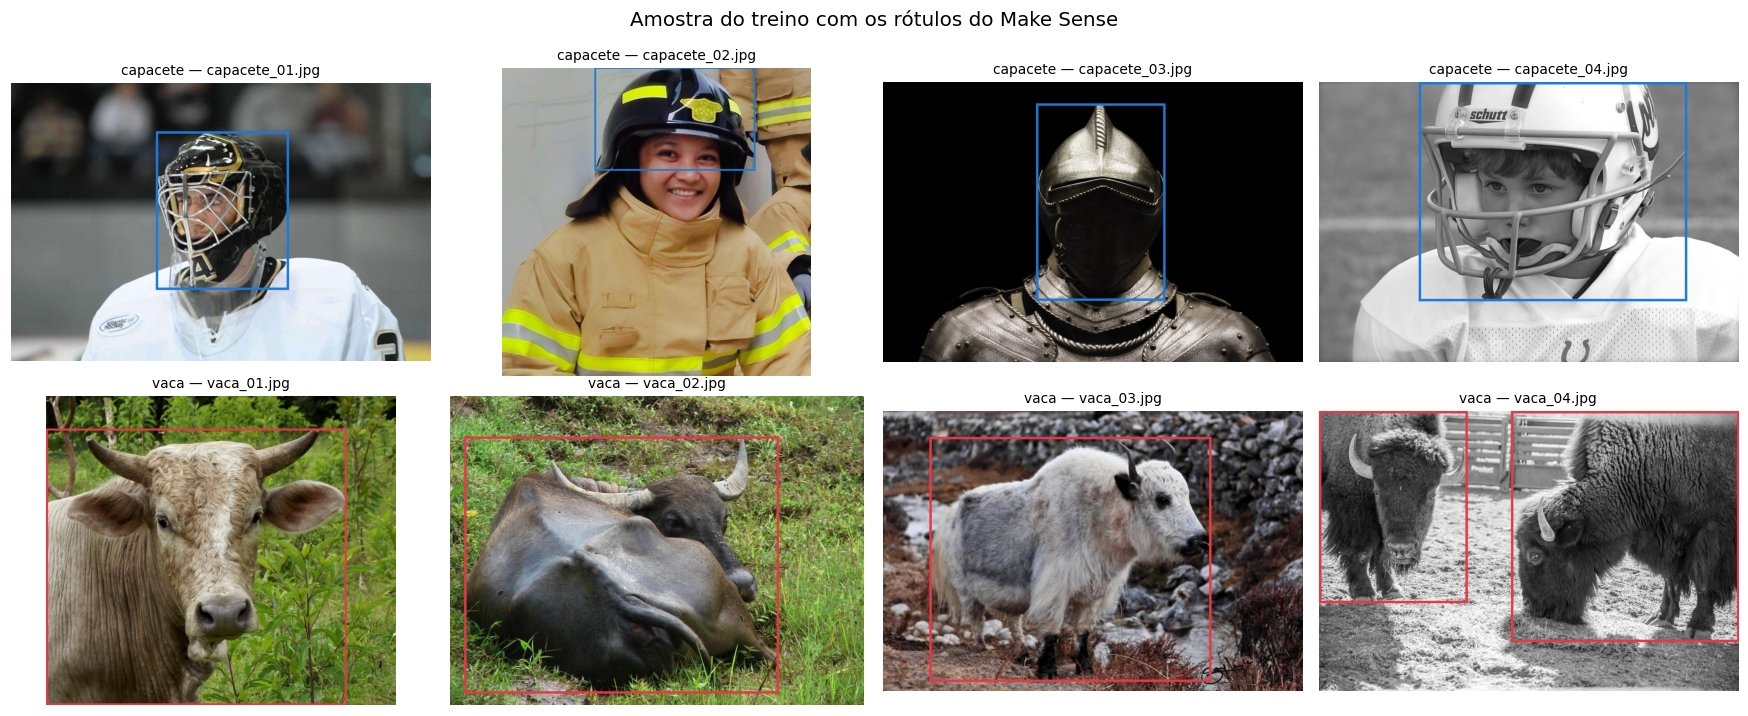

In [7]:
CORES = ["#e63946", "#1d7ad6"]  # uma cor por classe


def desenhar_rotulos(img):
    # Devolve a imagem com as caixas do rótulo desenhadas
    im = Image.open(img).convert("RGB")
    larg, alt = im.size
    pincel = ImageDraw.Draw(im)
    for c, xc, yc, w, h in ler_caixas(img):
        caixa = [(xc - w / 2) * larg, (yc - h / 2) * alt, (xc + w / 2) * larg, (yc + h / 2) * alt]
        pincel.rectangle(caixa, outline=CORES[int(c) % len(CORES)], width=max(3, larg // 150))
    return im


def mostrar_grade(imagens, titulos, colunas=4, titulo=None):
    # Exibe uma lista de imagens (caminhos, PIL ou arrays) em grade
    linhas = math.ceil(len(imagens) / colunas)
    fig, eixos = plt.subplots(linhas, colunas, figsize=(4 * colunas, 3.3 * linhas), squeeze=False)
    for ax in eixos.ravel():
        ax.axis("off")
    for ax, im, t in zip(eixos.ravel(), imagens, titulos):
        ax.imshow(Image.open(im) if isinstance(im, (str, Path)) else im)
        ax.set_title(t, fontsize=9)
    if titulo:
        fig.suptitle(titulo, fontsize=13)
    plt.tight_layout()
    plt.show()


# Quatro imagens de treino de cada classe
amostra = df_ds[df_ds["split"] == "train"].groupby("classe").head(4)
mostrar_grade(
    [desenhar_rotulos(p) for p in amostra["path"]],
    [f"{CLASSES[c]} — {p.name}" for p, c in zip(amostra["path"], amostra["classe"])],
    titulo="Amostra do treino com os rótulos do Make Sense",
)

O YOLOv5 recebe a descrição do dataset por um arquivo YAML com os caminhos dos
três conjuntos e os nomes das classes.

In [8]:
# Gera o YAML do dataset a partir da configuração
DATA_YAML.write_text(
    yaml.safe_dump(
        {
            "path": str(DS),
            "train": "images/train",
            "val": "images/val",
            "test": "images/test",
            "names": dict(enumerate(CLASSES)),
        },
        allow_unicode=True,
        sort_keys=False,
    )
)
print(DATA_YAML.read_text())

path: /content/dataset_local
train: images/train
val: images/val
test: images/test
names:
  0: vaca
  1: capacete



## 4. Treinamento: duas simulações

Usamos o **YOLOv5s** (versão "small") partindo dos pesos pré-treinados no COCO —
ou seja, *transfer learning*: a rede já sabe extrair bordas, texturas e formas, e
só precisa aprender a reconhecer as nossas duas classes. Com apenas 64 imagens de
treino, começar do zero não seria viável.

As duas simulações são **idênticas em tudo, exceto no número de épocas**: mesmos
pesos iniciais, mesmas imagens, mesma resolução, mesmo lote e mesma semente. Assim,
qualquer diferença nos resultados pode ser atribuída à duração do treino.

| Parâmetro | Valor | Significado |
|-----------|-------|-------------|
| `--weights` | `yolov5s.pt` | Pesos iniciais pré-treinados no COCO. |
| `--img` | 640 | Imagens redimensionadas para 640×640. |
| `--batch` | 16 | Imagens processadas por passo de otimização. |
| `--epochs` | 30 e 60 | Quantas vezes a rede vê o conjunto de treino inteiro. |
| `--seed` | 42 | Semente fixa, para o experimento ser reproduzível. |

O tempo medido é o de relógio do comando completo (inclui carregar o modelo e a
validação ao fim de cada época), que é o custo real percebido por quem treina.

In [9]:
def treinar(nome, epocas):
    # Treina o YOLOv5s e devolve a pasta do experimento e o tempo gasto em segundos
    inicio = time.time()
    !{sys.executable} {YOLO_DIR}/train.py --img {IMG_SIZE} --batch {BATCH} --epochs {epocas} --data {DATA_YAML} --weights {PESOS_BASE} --project {RUNS} --name {nome} --exist-ok --seed {SEED} --workers 2 --device {DEVICE}
    return RUNS / nome, time.time() - inicio


# Um registro por simulação: nome -> {épocas, pasta, tempo de treino}
simulacoes = {}

### Simulação A — menos épocas

In [10]:
nome_a = f"yolo_{EPOCHS_A}ep"
pasta, segundos = treinar(nome_a, EPOCHS_A)
simulacoes[nome_a] = {"epocas": EPOCHS_A, "pasta": pasta, "treino_s": segundos}
print(f"\nSimulação A concluída em {segundos / 60:.1f} min")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791908150.074686    3069 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=/content/yolov5s.pt, cfg=, data=/content/fase6_data.yaml, hyp=yolov5/data/hyps/hyp.scratch-low.yaml, epochs=30, batch_size

### Simulação B — mais épocas

In [11]:
nome_b = f"yolo_{EPOCHS_B}ep"
pasta, segundos = treinar(nome_b, EPOCHS_B)
simulacoes[nome_b] = {"epocas": EPOCHS_B, "pasta": pasta, "treino_s": segundos}
print(f"\nSimulação B concluída em {segundos / 60:.1f} min")

WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791908305.171427    3820 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=/content/yolov5s.pt, cfg=, data=/content/fase6_data.yaml, hyp=yolov5/data/hyps/hyp.scratch-low.yaml, epochs=60, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=yolov5/data/hyps, resume_evolve=None, bucket=, cache=None, image_weights=False, device=0, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, w

## 5. Evolução do treino: acurácia e erro por época

O YOLOv5 grava em `results.csv` as métricas de cada época. Como ler os gráficos:

- **Precisão** — das caixas que o modelo desenhou, quantas estavam certas
  (poucos alarmes falsos).
- **Recall** — dos objetos que existiam, quantos o modelo encontrou (poucos
  objetos perdidos).
- **mAP@0.5** — nota geral de detecção, aceitando caixas com pelo menos 50% de
  sobreposição com o rótulo.
- **mAP@0.5:0.95** — a mesma nota, mas exigindo caixas cada vez mais justas; é a
  métrica mais rigorosa e a que o YOLO usa para escolher o `best.pt`.
- **Loss (erro)** — soma dos erros de posição da caixa, de presença de objeto e
  de classe. A de **treino** mede o ajuste aos dados vistos; a de **validação**,
  a capacidade de generalizar. Treino caindo com validação subindo é o sinal
  clássico de *overfitting*.

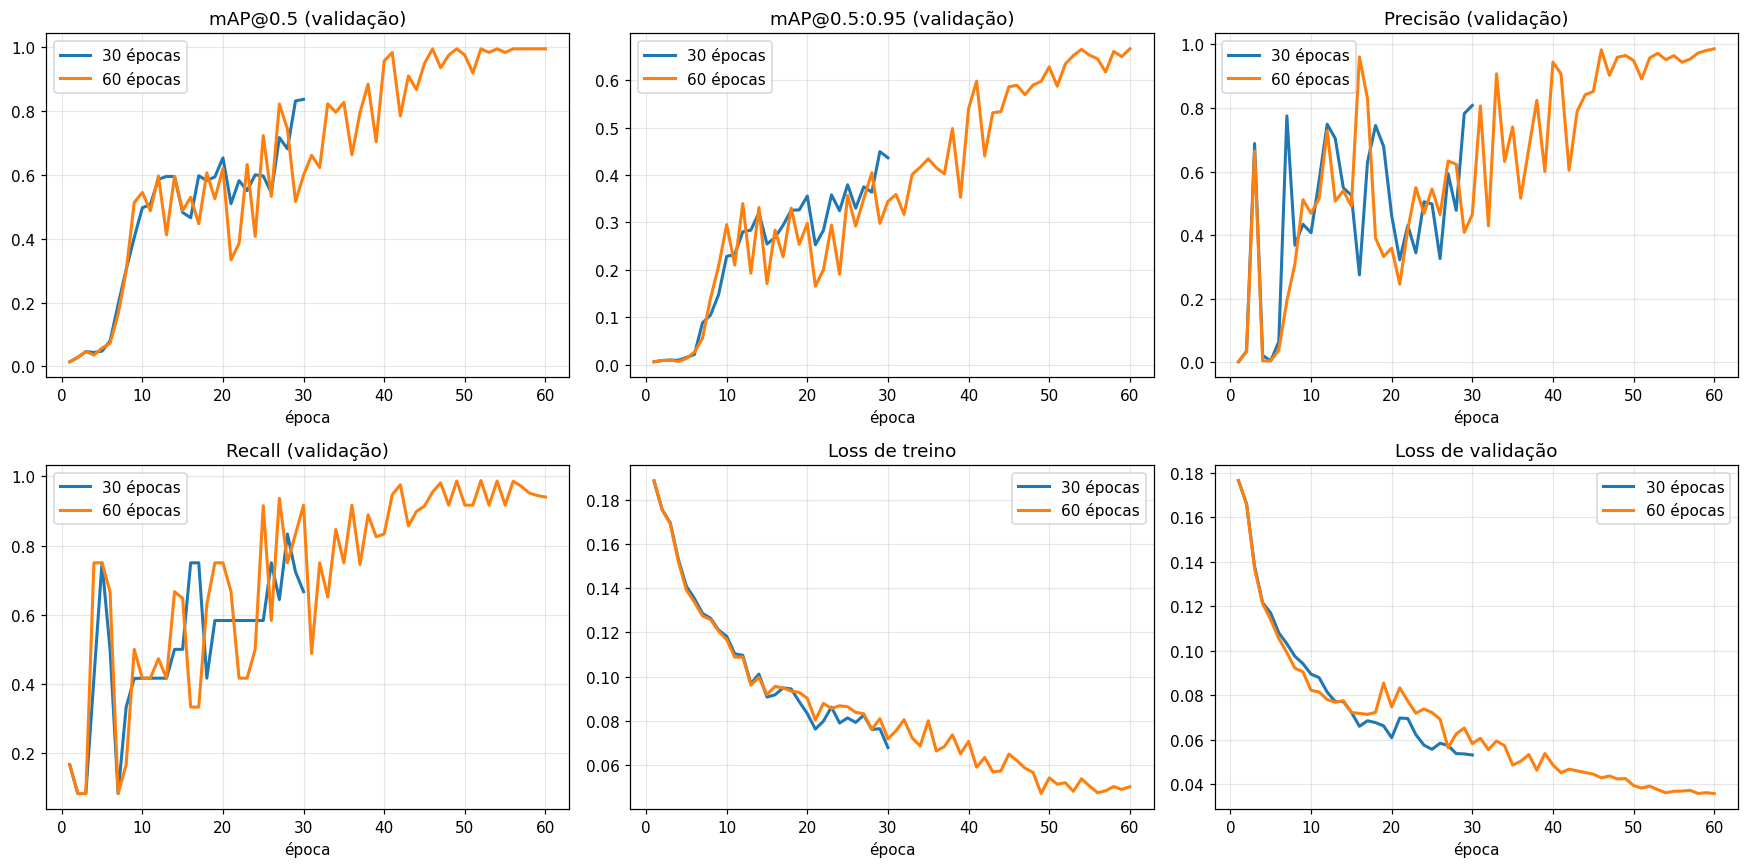

In [12]:
def ler_resultados(pasta):
    # Lê o results.csv do YOLOv5 e acrescenta as losses totais e o "fitness" de cada época
    df = pd.read_csv(pasta / "results.csv")
    df.columns = df.columns.str.strip()
    df["epoca"] = np.arange(1, len(df) + 1)
    df["loss_treino"] = df[["train/box_loss", "train/obj_loss", "train/cls_loss"]].sum(axis=1)
    df["loss_val"] = df[["val/box_loss", "val/obj_loss", "val/cls_loss"]].sum(axis=1)
    # Mesmo critério que o YOLOv5 usa para eleger o best.pt
    df["fitness"] = 0.1 * df["metrics/mAP_0.5"] + 0.9 * df["metrics/mAP_0.5:0.95"]
    return df


for sim in simulacoes.values():
    sim["hist"] = ler_resultados(sim["pasta"])

# Seis painéis com as duas simulações sobrepostas
paineis = [
    ("metrics/mAP_0.5", "mAP@0.5 (validação)"),
    ("metrics/mAP_0.5:0.95", "mAP@0.5:0.95 (validação)"),
    ("metrics/precision", "Precisão (validação)"),
    ("metrics/recall", "Recall (validação)"),
    ("loss_treino", "Loss de treino"),
    ("loss_val", "Loss de validação"),
]
fig, eixos = plt.subplots(2, 3, figsize=(16, 8))
for ax, (coluna, titulo) in zip(eixos.ravel(), paineis):
    for nome, sim in simulacoes.items():
        ax.plot(sim["hist"]["epoca"], sim["hist"][coluna], label=f"{sim['epocas']} épocas", linewidth=2)
    ax.set_title(titulo)
    ax.set_xlabel("época")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## 6. Validação e teste com o melhor peso de cada simulação

Cada treino salva dois arquivos de pesos: `last.pt` (última época) e `best.pt`
(a época de melhor desempenho na validação). Avaliamos o `best.pt` de cada
simulação com o `val.py` do YOLOv5 em dois conjuntos:

- **Validação** — as 8 imagens que guiaram a escolha do `best.pt`; o resultado
  tende a ser otimista justamente por isso.
- **Teste** — as 8 imagens que o modelo nunca viu, nem direta nem indiretamente;
  é a estimativa mais honesta do desempenho em uso real.

In [13]:
def avaliar_yolo(pesos, split, nome):
    # Roda o val.py em um conjunto e devolve precisão, recall, mAP@0.5 e mAP@0.5:0.95 gerais
    comando = [
        sys.executable, str(YOLO_DIR / "val.py"), "--weights", str(pesos), "--data", str(DATA_YAML),
        "--img", str(IMG_SIZE), "--task", split, "--project", str(RUNS), "--name", nome,
        "--exist-ok", "--device", DEVICE,
    ]
    execucao = subprocess.run(comando, capture_output=True, text=True)
    saida = (execucao.stdout + execucao.stderr).replace("\r", "\n")
    # A linha "all" traz: nº de imagens, nº de objetos, P, R, mAP50, mAP50-95
    geral = re.search(r"^\s*all\s+\d+\s+\d+\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)", saida, re.M)
    assert geral, saida[-2000:]
    # Mostra a tabela por classe impressa pelo YOLO
    nomes = "|".join(["Class", "all"] + CLASSES)
    print(f"--- {nome} ---")
    print("\n".join(l for l in saida.splitlines() if re.match(rf"\s*({nomes})\s", l) and "%" not in l))
    return dict(zip(["P", "R", "mAP50", "mAP50-95"], map(float, geral.groups())))


for nome, sim in simulacoes.items():
    sim["best"] = sim["pasta"] / "weights" / "best.pt"
    sim["val"] = avaliar_yolo(sim["best"], "val", f"val_{nome}")
    sim["test"] = avaliar_yolo(sim["best"], "test", f"test_{nome}")

--- val_yolo_30ep ---
                   all          8         12      0.783      0.734       0.82      0.438
                  vaca          8          6      0.833          1      0.972       0.65
              capacete          8          6      0.734      0.467      0.669      0.226
--- test_yolo_30ep ---
                   all          8         11      0.957       0.74      0.902      0.445
                  vaca          8          6          1      0.881      0.995      0.583
              capacete          8          5      0.914        0.6      0.809      0.307
--- val_yolo_60ep ---
                   all          8         12      0.986       0.94      0.995      0.666
                  vaca          8          6      0.973          1      0.995      0.796
              capacete          8          6          1      0.879      0.995      0.535
--- test_yolo_60ep ---
                   all          8         11      0.862        0.9      0.946      0.649
                  va

In [14]:
# Tabela-resumo das duas simulações
linhas = []
for nome, sim in simulacoes.items():
    hist = sim["hist"]
    linhas.append(
        {
            "simulação": nome,
            "épocas": sim["epocas"],
            "treino (min)": sim["treino_s"] / 60,
            "melhor época": int(hist.loc[hist["fitness"].idxmax(), "epoca"]),
            "loss treino final": hist["loss_treino"].iloc[-1],
            "loss val final": hist["loss_val"].iloc[-1],
            "época da menor loss val": int(hist.loc[hist["loss_val"].idxmin(), "epoca"]),
            **{f"val {k}": v for k, v in sim["val"].items()},
            **{f"teste {k}": v for k, v in sim["test"].items()},
        }
    )
resumo_yolo = pd.DataFrame(linhas).set_index("simulação")
display(resumo_yolo.T.style.format(precision=3))

simulação,yolo_30ep,yolo_60ep
épocas,30.000,60.000
treino (min),2.717,3.765
melhor época,29.000,60.000
loss treino final,0.068,0.050
loss val final,0.053,0.036
época da menor loss val,30.000,60.000
val P,0.783,0.986
val R,0.734,0.940
val mAP50,0.820,0.995
val mAP50-95,0.438,0.666


A matriz de confusão do conjunto de teste mostra *que tipo* de erro cada modelo
comete: confundir uma classe com a outra, deixar de detectar um objeto (coluna
`background`) ou detectar algo onde não havia nada (linha `background`).

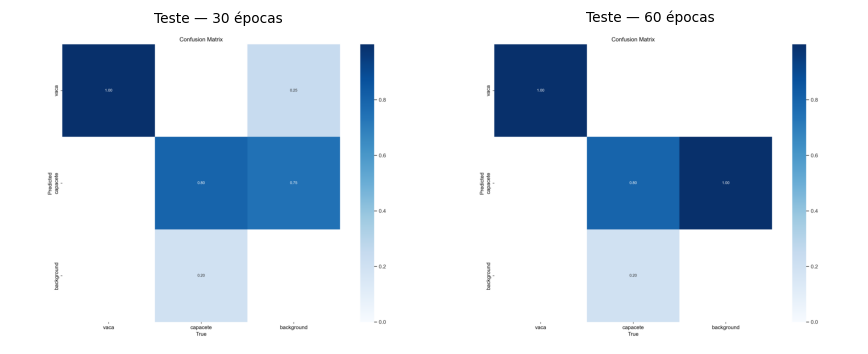

In [15]:
mostrar_grade(
    [RUNS / f"test_{nome}" / "confusion_matrix.png" for nome in simulacoes],
    [f"Teste — {sim['epocas']} épocas" for sim in simulacoes.values()],
    colunas=2,
)

## 7. O modelo em ação: imagens de teste processadas

Números convencem o time técnico; para o cliente, o que convence é **ver o
modelo funcionando**. Rodamos o `detect.py` nas 8 imagens de teste com o
`best.pt` de cada simulação. Cada caixa traz a classe prevista e a confiança
(de 0 a 1); detecções com confiança abaixo de 0,25 são descartadas.

Por padrão o YOLOv5 salva em `yolov5/runs/detect/expX`; aqui usamos `--project`
e `--name` para dar nomes explícitos às pastas (`runs_fase6/detect_<simulação>`).

In [16]:
for nome, sim in simulacoes.items():
    pesos, sim["detect"] = sim["best"], RUNS / f"detect_{nome}"
    !{sys.executable} {YOLO_DIR}/detect.py --weights {pesos} --source {DS}/images/test --img {IMG_SIZE} --conf-thres 0.25 --project {RUNS} --name detect_{nome} --exist-ok --device {DEVICE}

detect: weights=['/content/runs_fase6/yolo_30ep/weights/best.pt'], source=/content/dataset_local/images/test, data=yolov5/data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=0, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=/content/runs_fase6, name=detect_yolo_30ep, exist_ok=True, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 f957879 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
image 1/8 /content/dataset_local/images/test/capacete_37.jpg: 448x640 1 capacete, 40.1ms
image 2/8 /content/dataset_local/images/test/capacete_38.jpg: 448x640 1 capacete, 12.3ms
image 3/8 /content/dataset_local/images/test/capacete_39.jpg: 448x640 2 capacetes, 12.2ms
image 4/8 /con

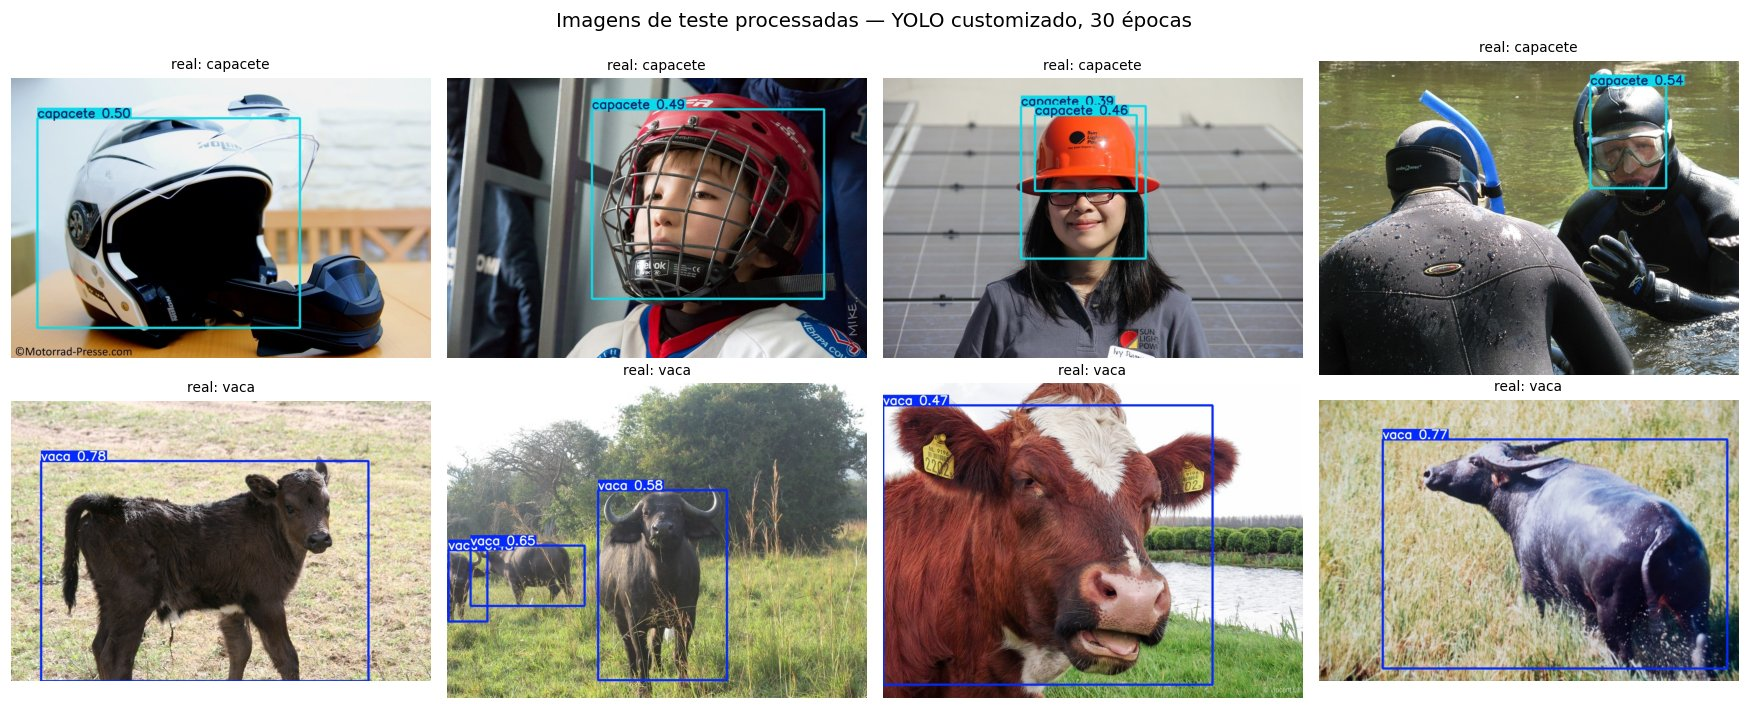

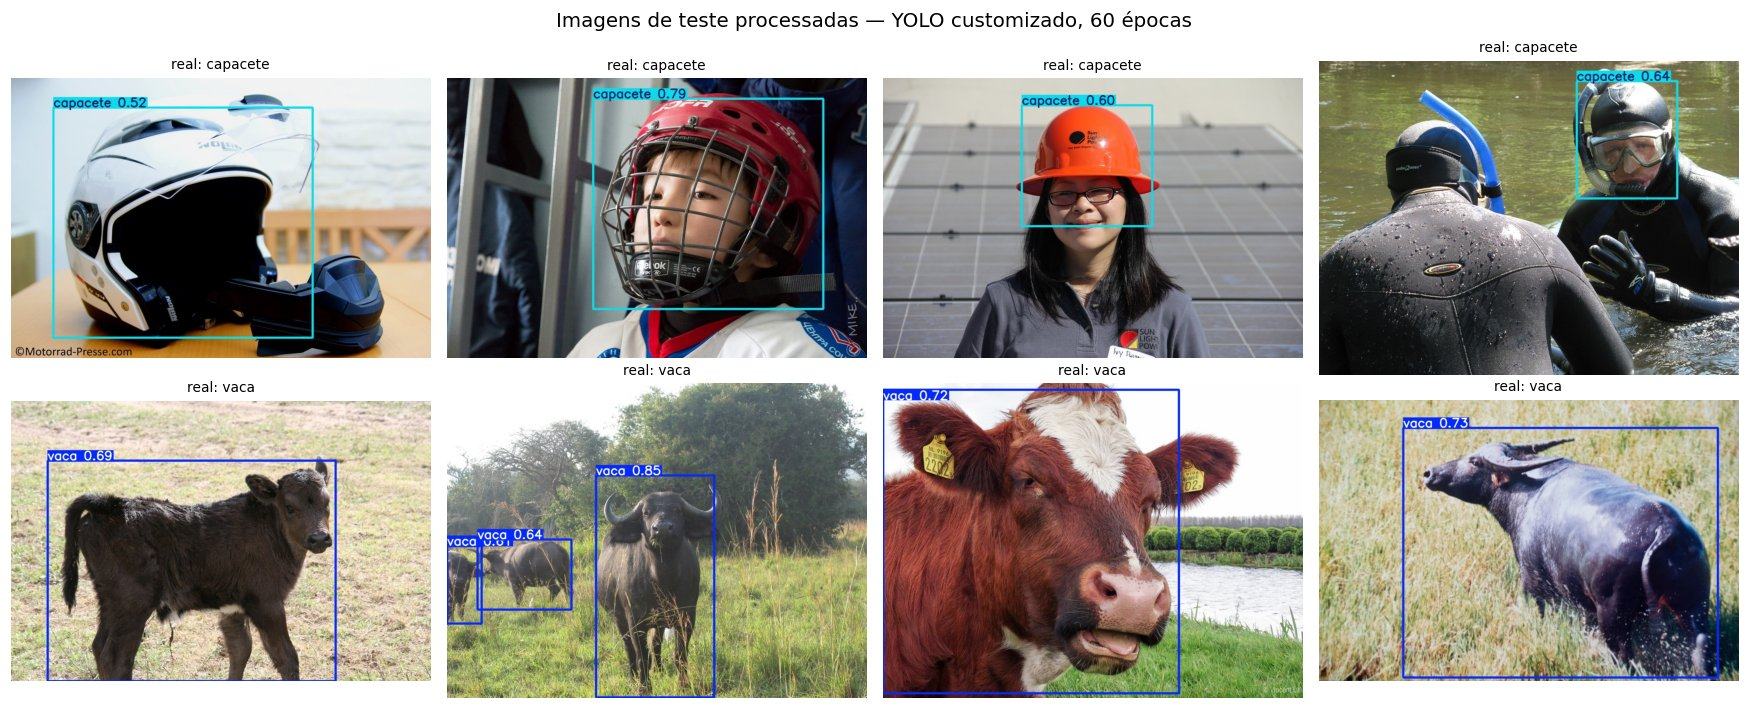

In [17]:
teste = df_ds[df_ds["split"] == "test"].reset_index(drop=True)
for nome, sim in simulacoes.items():
    mostrar_grade(
        [sim["detect"] / p.name for p in teste["path"]],
        [f"real: {CLASSES[c]}" for c in teste["classe"]],
        titulo=f"Imagens de teste processadas — YOLO customizado, {sim['epocas']} épocas",
    )

## 8. Conclusões da Entrega 1

A célula abaixo redige a comparação entre as duas simulações a partir dos números
medidos nesta execução.

In [18]:
a, b = (resumo_yolo.loc[n] for n in simulacoes)
ganho = b["teste mAP50-95"] - a["teste mAP50-95"]
custo = b["treino (min)"] / a["treino (min)"]

# Veredito sobre o treino mais longo (0,02 de mAP é a margem que tratamos como ruído)
if ganho > 0.02:
    veredito = f"O treino mais longo **compensou**: +{ganho:.3f} de mAP@0.5:0.95 no teste."
elif ganho < -0.02:
    veredito = (
        f"O treino mais longo **piorou** o resultado no teste ({ganho:.3f} de mAP@0.5:0.95), "
        "indício de que a rede passou a memorizar o treino (*overfitting*)."
    )
else:
    veredito = (
        f"As duas simulações ficaram em **empate técnico** no teste (diferença de {ganho:+.3f} de "
        "mAP@0.5:0.95): dobrar as épocas não trouxe ganho proporcional ao custo."
    )

# A loss de validação ainda caía no fim do treino longo, ou já tinha parado?
ep_min = int(b["época da menor loss val"])
if ep_min < 0.8 * b["épocas"]:
    tendencia = (
        f"Na simulação longa, a loss de validação atingiu o mínimo na época {ep_min} de "
        f"{int(b['épocas'])} e não melhorou depois, enquanto a de treino seguiu caindo — a partir daí "
        "o modelo se ajusta mais ao treino do que aprende a generalizar."
    )
else:
    tendencia = (
        f"Na simulação longa, a loss de validação ainda atingia o mínimo perto do fim (época {ep_min} "
        f"de {int(b['épocas'])}), sinal de que o modelo ainda estava aprendendo e de que mais épocas "
        "poderiam ajudar."
    )

display(Markdown(f'''
### Resultados medidos

| | {int(a["épocas"])} épocas | {int(b["épocas"])} épocas |
|---|---:|---:|
| Tempo de treino | {a["treino (min)"]:.1f} min | {b["treino (min)"]:.1f} min |
| Época do `best.pt` | {int(a["melhor época"])} | {int(b["melhor época"])} |
| Loss de validação final | {a["loss val final"]:.4f} | {b["loss val final"]:.4f} |
| **Validação** — precisão / recall | {a["val P"]:.3f} / {a["val R"]:.3f} | {b["val P"]:.3f} / {b["val R"]:.3f} |
| **Validação** — mAP@0.5 / mAP@0.5:0.95 | {a["val mAP50"]:.3f} / {a["val mAP50-95"]:.3f} | {b["val mAP50"]:.3f} / {b["val mAP50-95"]:.3f} |
| **Teste** — precisão / recall | {a["teste P"]:.3f} / {a["teste R"]:.3f} | {b["teste P"]:.3f} / {b["teste R"]:.3f} |
| **Teste** — mAP@0.5 / mAP@0.5:0.95 | {a["teste mAP50"]:.3f} / {a["teste mAP50-95"]:.3f} | {b["teste mAP50"]:.3f} / {b["teste mAP50-95"]:.3f} |

### Leitura dos resultados

- **Acurácia.** {veredito}
- **Erro.** {tendencia}
- **Desempenho.** A simulação de {int(b["épocas"])} épocas levou **{custo:.1f}×** o tempo da de
  {int(a["épocas"])} épocas. O tempo de *inferência* não muda com as épocas: a arquitetura é a
  mesma, só os pesos diferem.
- **Validação × teste.** A diferença entre os dois conjuntos mede o quanto a validação foi
  otimista. Com apenas 8 imagens em cada um, variações de alguns pontos são esperadas.
'''))


### Resultados medidos

| | 30 épocas | 60 épocas |
|---|---:|---:|
| Tempo de treino | 2.7 min | 3.8 min |
| Época do `best.pt` | 29 | 60 |
| Loss de validação final | 0.0532 | 0.0359 |
| **Validação** — precisão / recall | 0.783 / 0.734 | 0.986 / 0.940 |
| **Validação** — mAP@0.5 / mAP@0.5:0.95 | 0.820 / 0.438 | 0.995 / 0.666 |
| **Teste** — precisão / recall | 0.957 / 0.740 | 0.862 / 0.900 |
| **Teste** — mAP@0.5 / mAP@0.5:0.95 | 0.902 / 0.445 | 0.946 / 0.649 |

### Leitura dos resultados

- **Acurácia.** O treino mais longo **compensou**: +0.204 de mAP@0.5:0.95 no teste.
- **Erro.** Na simulação longa, a loss de validação ainda atingia o mínimo perto do fim (época 60 de 60), sinal de que o modelo ainda estava aprendendo e de que mais épocas poderiam ajudar.
- **Desempenho.** A simulação de 60 épocas levou **1.4×** o tempo da de
  30 épocas. O tempo de *inferência* não muda com as épocas: a arquitetura é a
  mesma, só os pesos diferem.
- **Validação × teste.** A diferença entre os dois conjuntos mede o quanto a validação foi
  otimista. Com apenas 8 imagens em cada um, variações de alguns pontos são esperadas.


### Pontos fortes

- **Pouco dado, bom resultado.** Partir de pesos pré-treinados permite treinar um
  detector com apenas 64 imagens rotuladas, em minutos, numa GPU gratuita.
- **Comparação controlada.** As simulações diferem só no número de épocas, então
  a diferença de resultado tem causa única.
- **Avaliação em dados nunca vistos.** O conjunto de teste não participa nem do
  treino nem da escolha do `best.pt`.

### Limitações

- **Conjuntos de validação e teste minúsculos.** Com 8 imagens, um único objeto
  perdido muda as métricas em vários pontos percentuais; as diferenças entre as
  simulações precisam ser lidas com essa margem em mente.
- **Dataset pouco variado.** 40 imagens por classe não cobrem variações de
  iluminação, ângulo, distância, oclusão e fundo que aparecem no campo.
- **Uma única execução por configuração.** O treino tem componentes aleatórios;
  o ideal seria repetir cada simulação com sementes diferentes e reportar a média.
- **Apenas duas classes.** O modelo só conhece esses dois objetos; qualquer outra
  coisa na cena será ignorada ou, pior, confundida com um deles.

Para um piloto real com o cliente, o próximo passo seria ampliar o dataset com
fotos tiradas no ambiente de uso e reservar um conjunto de teste maior.

---
# Entrega 2 — Abordagens concorrentes

O YOLO customizado funcionou, mas ele é a melhor escolha? Comparamos com duas
alternativas usando a **mesma base de imagens**:

| Abordagem | O que é | Precisa de treino? | O que responde |
|-----------|---------|--------------------|----------------|
| **YOLO customizado** (Entrega 1) | YOLOv5s ajustado às nossas classes | Sim, com caixas rotuladas | *O que* é e *onde* está |
| **YOLO padrão** | YOLOv5s como vem de fábrica, treinado nas 80 classes do COCO | Não | *O que* é e *onde* está, mas só para classes do COCO |
| **CNN do zero** | Rede convolucional pequena, pesos iniciais aleatórios | Sim, só com a classe da imagem | Apenas *o que* é |

### Uma régua comum

Detectores são medidos por mAP e classificadores por acurácia — métricas que não
se comparam diretamente. Para colocar as três abordagens na mesma régua,
reduzimos tudo à pergunta que a CNN sabe responder: **"qual das duas classes
aparece nesta imagem?"**

- Para os modelos YOLO, a classe da imagem é a da **detecção de maior confiança**
  entre as classes de interesse. Se nada for detectado, conta como erro.
- A medida é a **acurácia nas 8 imagens de teste**, as mesmas para todos.
- O **tempo de inferência** é medido do mesmo jeito para todos: tempo médio por
  imagem, do arquivo em disco até a resposta, após uma execução de aquecimento.

In [19]:
def medir(prever, imagens):
    # Aplica `prever` a cada imagem e devolve as predições e o tempo médio por imagem (ms)
    prever(imagens[0])  # aquecimento: a 1ª chamada inclui alocações que não se repetem
    inicio = time.perf_counter()
    predicoes = [prever(p) for p in imagens]
    return np.array(predicoes), 1000 * (time.perf_counter() - inicio) / len(imagens)


def carregar_yolo(pesos):
    # Carrega um YOLOv5 (customizado ou padrão) pronto para inferência em Python
    return torch.hub.load(str(YOLO_DIR), "custom", path=str(pesos), source="local", verbose=False)


def classe_por_yolo(modelo, mapa):
    # Cria a função imagem -> classe: detecção mais confiante entre os nomes de `mapa` (-1 = nada)
    def prever(img):
        det = modelo(str(img), size=IMG_SIZE).pandas().xyxy[0]
        det = det[det["name"].isin(mapa)]
        return mapa[det.loc[det["confidence"].idxmax(), "name"]] if len(det) else -1

    return prever


imgs_teste = list(teste["path"])
y_teste = teste["classe"].to_numpy()
comparacao = []  # uma linha por abordagem


def registrar(abordagem, y_pred, ms, treino_min, map50=np.nan):
    # Acrescenta uma abordagem à tabela comparativa final
    comparacao.append(
        {
            "abordagem": abordagem,
            "acertos": f"{int((y_pred == y_teste).sum())}/{len(y_teste)}",
            "acurácia (teste)": (y_pred == y_teste).mean(),
            "sem detecção": int((y_pred == -1).sum()),
            "mAP@0.5 (teste)": map50,
            "treino (min)": treino_min,
            "inferência (ms/img)": ms,
        }
    )

## 9. YOLO customizado na régua comum

Primeiro medimos os dois modelos da Entrega 1 com o novo critério.

In [20]:
mapa_custom = {nome: i for i, nome in enumerate(CLASSES)}
for nome, sim in simulacoes.items():
    y_pred, ms = medir(classe_por_yolo(carregar_yolo(sim["best"]), mapa_custom), imgs_teste)
    registrar(f"YOLO customizado ({sim['epocas']} ép.)", y_pred, ms, sim["treino_s"] / 60, sim["test"]["mAP50"])
    print(f"{nome}: acurácia {np.mean(y_pred == y_teste):.3f} | {ms:.1f} ms por imagem")

YOLOv5 🚀 f957879 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
yolo_30ep: acurácia 1.000 | 28.1 ms por imagem
YOLOv5 🚀 f957879 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
yolo_60ep: acurácia 1.000 | 22.6 ms por imagem


## 10. YOLO padrão (pré-treinado no COCO)

O YOLO "tradicional" é o mesmo YOLOv5s, mas usado como vem de fábrica: os pesos
`yolov5s.pt` treinados nas **80 classes do COCO** (pessoa, carro, cachorro,
vaca, xícara...). Não há treino nem rotulação: basta carregar e usar.

A limitação é direta — ele só reconhece o que está na lista do COCO. O dicionário
`COCO_EQUIV` da configuração registra, para cada uma das nossas classes, qual é a
classe equivalente no COCO (ou `None` quando não existe). Uma classe sem
equivalente **nunca será acertada** por este modelo, por melhor que ele seja.

In [21]:
yolo_padrao = carregar_yolo(PESOS_BASE)
nomes_coco = set(yolo_padrao.names.values())

# Confere a equivalência declarada na configuração
mapa_coco = {}
for i, classe in enumerate(CLASSES):
    equivalente = COCO_EQUIV.get(classe)
    assert equivalente is None or equivalente in nomes_coco, f"'{equivalente}' não é uma classe do COCO"
    print(f"{classe:>12} -> {equivalente or 'sem equivalente no COCO'}")
    if equivalente:
        mapa_coco[equivalente] = i

y_pred_padrao, ms_padrao = medir(classe_por_yolo(yolo_padrao, mapa_coco), imgs_teste)
registrar("YOLO padrão (COCO)", y_pred_padrao, ms_padrao, 0.0)
print(f"\nAcurácia: {np.mean(y_pred_padrao == y_teste):.3f} | {ms_padrao:.1f} ms por imagem")

YOLOv5 🚀 f957879 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 
        vaca -> cow
    capacete -> sem equivalente no COCO

Acurácia: 0.500 | 22.0 ms por imagem


Para entender *por que* o YOLO padrão acerta ou erra, a tabela abaixo lista tudo
o que ele enxergou em cada imagem de teste, e a grade mostra as caixas desenhadas.
É comum ele detectar o objeto corretamente como "alguma coisa", mas com o nome da
classe mais parecida que conhece.

,imagem,classe real,equivalente COCO,o que o YOLO padrão viu
0,capacete_37.jpg,capacete,—,cell phone (0.44)
1,capacete_38.jpg,capacete,—,person (0.35)
2,capacete_39.jpg,capacete,—,person (0.93)
3,capacete_40.jpg,capacete,—,person (0.57)
4,vaca_37.jpg,vaca,cow,cow (0.77)
5,vaca_38.jpg,vaca,cow,"cow (0.92), cow (0.83), cow (0.80)"
6,vaca_39.jpg,vaca,cow,cow (0.60)
7,vaca_40.jpg,vaca,cow,"sheep (0.51), cow (0.49)"


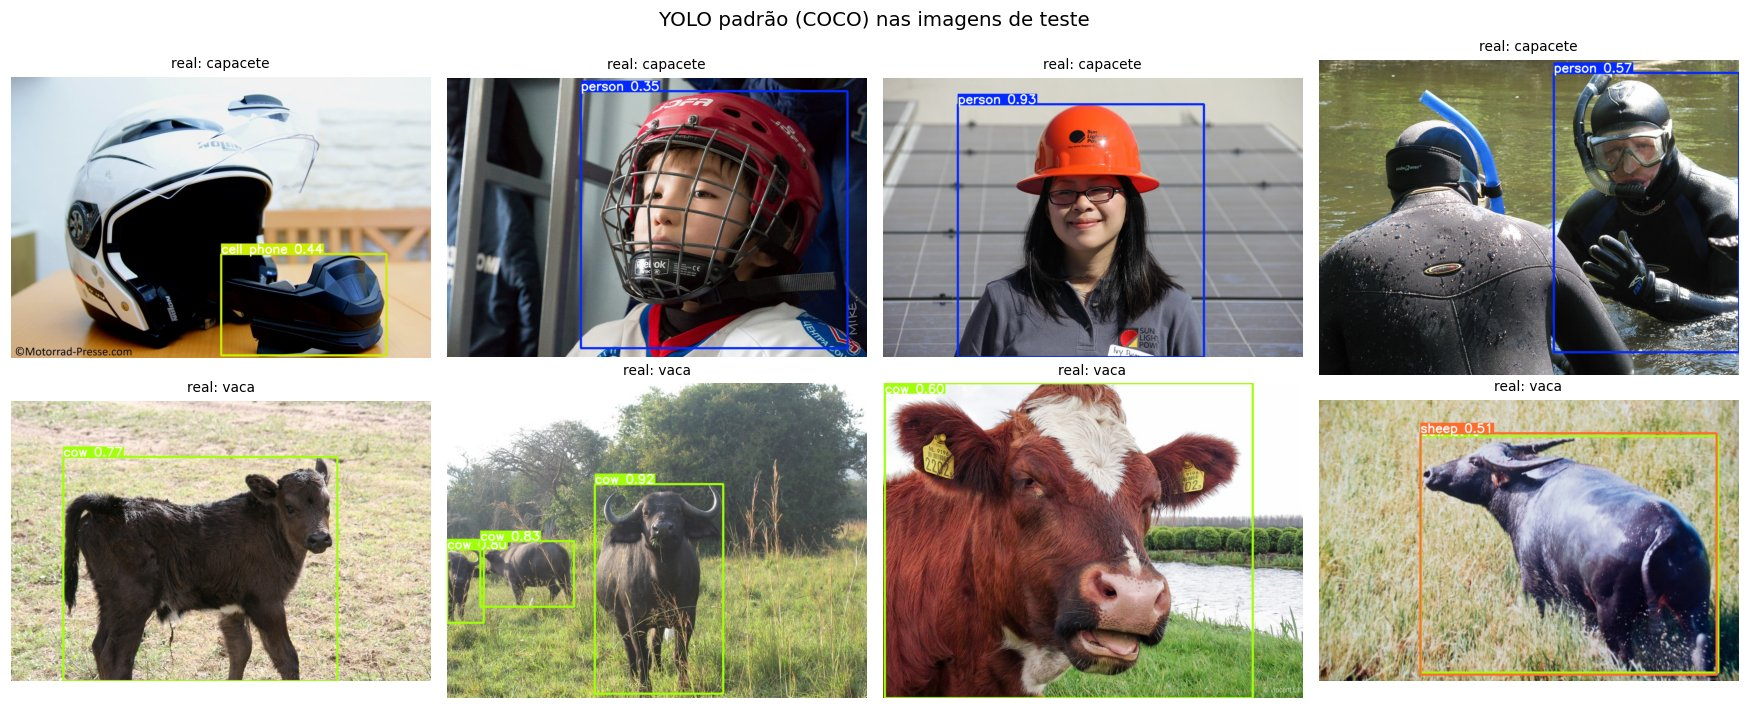

In [22]:
linhas, renderizadas = [], []
for p, c in zip(imgs_teste, y_teste):
    resultado = yolo_padrao(str(p), size=IMG_SIZE)
    det = resultado.pandas().xyxy[0].sort_values("confidence", ascending=False)
    linhas.append(
        {
            "imagem": p.name,
            "classe real": CLASSES[c],
            "equivalente COCO": COCO_EQUIV.get(CLASSES[c]) or "—",
            "o que o YOLO padrão viu": ", ".join(f"{n} ({s:.2f})" for n, s in zip(det["name"], det["confidence"])) or "nada",
        }
    )
    renderizadas.append(resultado.render()[0])  # imagem com as caixas desenhadas

display(pd.DataFrame(linhas))
mostrar_grade(renderizadas, [f"real: {CLASSES[c]}" for c in y_teste], titulo="YOLO padrão (COCO) nas imagens de teste")

## 11. CNN treinada do zero

A terceira abordagem é uma rede convolucional pequena, **sem nenhum
pré-treino**: os pesos começam aleatórios e tudo o que a rede sabe vem das nossas
64 imagens de treino. Ela resolve um problema mais simples que o do YOLO —
apenas **classificar a imagem inteira**, sem dizer onde o objeto está — e por
isso só precisa da classe de cada imagem, não das caixas.

**Arquitetura.** Quatro blocos `Conv 3×3 → BatchNorm → ReLU → MaxPool`, com 16,
32, 64 e 128 filtros. Cada bloco reduz a resolução pela metade e dobra a
quantidade de padrões que a rede consegue representar: os primeiros aprendem
bordas e cores, os últimos, partes do objeto. Um *global average pooling* resume
o mapa final em 128 números, e uma camada densa decide a classe.

**Cuidados contra overfitting**, essenciais com tão poucos dados:

- *Data augmentation* no treino (espelhamento, rotação leve, variação de cor):
  cada época vê versões ligeiramente diferentes das mesmas imagens.
- *Dropout* de 30% antes da camada de decisão.
- Guardamos os pesos da época de **melhor acurácia de validação**, o mesmo papel
  do `best.pt` no YOLO.

In [23]:
DEV = torch.device("cuda" if TEM_GPU else "cpu")
NORMALIZAR = transforms.Normalize([0.5] * 3, [0.5] * 3)  # leva os pixels de [0, 1] para [-1, 1]

# Treino com augmentation; validação e teste apenas redimensionam
tf_treino = transforms.Compose(
    [
        transforms.Resize((CNN_SIZE, CNN_SIZE)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.ToTensor(),
        NORMALIZAR,
    ]
)
tf_aval = transforms.Compose([transforms.Resize((CNN_SIZE, CNN_SIZE)), transforms.ToTensor(), NORMALIZAR])


class ImagensDS(Dataset):
    # Dataset de classificação: devolve (imagem transformada, classe)
    def __init__(self, df, tf):
        self.caminhos, self.classes, self.tf = list(df["path"]), list(df["classe"]), tf

    def __len__(self):
        return len(self.caminhos)

    def __getitem__(self, i):
        return self.tf(Image.open(self.caminhos[i]).convert("RGB")), self.classes[i]


def bloco(entrada, saida):
    # Bloco convolucional: extrai padrões e reduz a resolução pela metade
    return nn.Sequential(
        nn.Conv2d(entrada, saida, kernel_size=3, padding=1),
        nn.BatchNorm2d(saida),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )


class CNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.extrator = nn.Sequential(bloco(3, 16), bloco(16, 32), bloco(32, 64), bloco(64, 128))
        self.decisor = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, n_classes))

    def forward(self, x):
        return self.decisor(self.extrator(x))


cnn = CNN(len(CLASSES)).to(DEV)
print(cnn)
print("Parâmetros treináveis:", sum(p.numel() for p in cnn.parameters()))

CNN(
  (extrator): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (3): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), strid

In [24]:
gerador = torch.Generator().manual_seed(SEED)  # embaralhamento reproduzível
dl_treino = DataLoader(ImagensDS(df_ds[df_ds["split"] == "train"], tf_treino), batch_size=BATCH, shuffle=True, generator=gerador)
dl_val = DataLoader(ImagensDS(df_ds[df_ds["split"] == "val"], tf_aval), batch_size=BATCH)

criterio = nn.CrossEntropyLoss()
otimizador = torch.optim.Adam(cnn.parameters(), lr=1e-3)


def passar_epoca(dl, treinando):
    # Percorre o conjunto uma vez; devolve loss média e acurácia
    cnn.train(treinando)
    soma_loss, acertos, total = 0.0, 0, 0
    with torch.set_grad_enabled(treinando):
        for x, y in dl:
            x, y = x.to(DEV), y.to(DEV)
            saida = cnn(x)
            loss = criterio(saida, y)
            if treinando:
                otimizador.zero_grad()
                loss.backward()
                otimizador.step()
            soma_loss += loss.item() * len(y)
            acertos += (saida.argmax(1) == y).sum().item()
            total += len(y)
    return soma_loss / total, acertos / total


hist_cnn, melhor = [], (-1.0, float("inf"))
inicio = time.time()
for epoca in range(1, CNN_EPOCHS + 1):
    loss_t, acc_t = passar_epoca(dl_treino, True)
    loss_v, acc_v = passar_epoca(dl_val, False)
    hist_cnn.append({"epoca": epoca, "loss_treino": loss_t, "acc_treino": acc_t, "loss_val": loss_v, "acc_val": acc_v})
    # Guarda os pesos da melhor época: maior acurácia de validação; no empate, menor loss
    if (acc_v, -loss_v) > (melhor[0], -melhor[1]):
        melhor, melhor_epoca = (acc_v, loss_v), epoca
        melhores_pesos = {k: v.detach().clone() for k, v in cnn.state_dict().items()}
    if epoca % 5 == 0 or epoca == 1:
        print(f"época {epoca:3d} | treino loss {loss_t:.3f} acc {acc_t:.3f} | val loss {loss_v:.3f} acc {acc_v:.3f}")
treino_cnn_s = time.time() - inicio

cnn.load_state_dict(melhores_pesos)
hist_cnn = pd.DataFrame(hist_cnn)
print(f"\nTreino da CNN: {treino_cnn_s:.1f} s | melhor época: {melhor_epoca} (acc val {melhor[0]:.3f})")

época   1 | treino loss 0.639 acc 0.656 | val loss 0.687 acc 0.625
época   5 | treino loss 0.414 acc 0.781 | val loss 0.684 acc 0.500
época  10 | treino loss 0.418 acc 0.766 | val loss 0.536 acc 0.750
época  15 | treino loss 0.300 acc 0.875 | val loss 0.477 acc 0.750
época  20 | treino loss 0.299 acc 0.875 | val loss 0.618 acc 0.750
época  25 | treino loss 0.399 acc 0.812 | val loss 0.492 acc 0.875
época  30 | treino loss 0.360 acc 0.859 | val loss 1.015 acc 0.625
época  35 | treino loss 0.253 acc 0.875 | val loss 0.456 acc 0.875
época  40 | treino loss 0.246 acc 0.938 | val loss 0.678 acc 0.750

Treino da CNN: 31.2 s | melhor época: 35 (acc val 0.875)


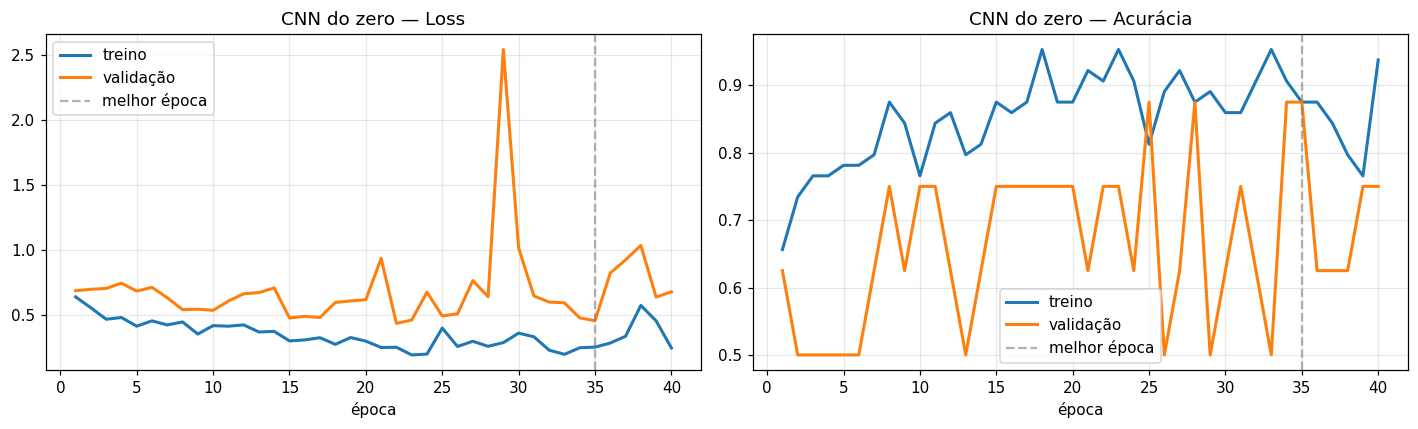

In [25]:
# Curvas de aprendizado da CNN
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for ax, metrica, titulo in [(ax1, "loss", "Loss"), (ax2, "acc", "Acurácia")]:
    ax.plot(hist_cnn["epoca"], hist_cnn[f"{metrica}_treino"], label="treino", linewidth=2)
    ax.plot(hist_cnn["epoca"], hist_cnn[f"{metrica}_val"], label="validação", linewidth=2)
    ax.axvline(melhor_epoca, color="gray", linestyle="--", alpha=0.6, label="melhor época")
    ax.set_title(f"CNN do zero — {titulo}")
    ax.set_xlabel("época")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

Acurácia no teste: 0.875 | 14.7 ms por imagem


previsto,vaca,capacete
real,,
vaca,3,1
capacete,0,4


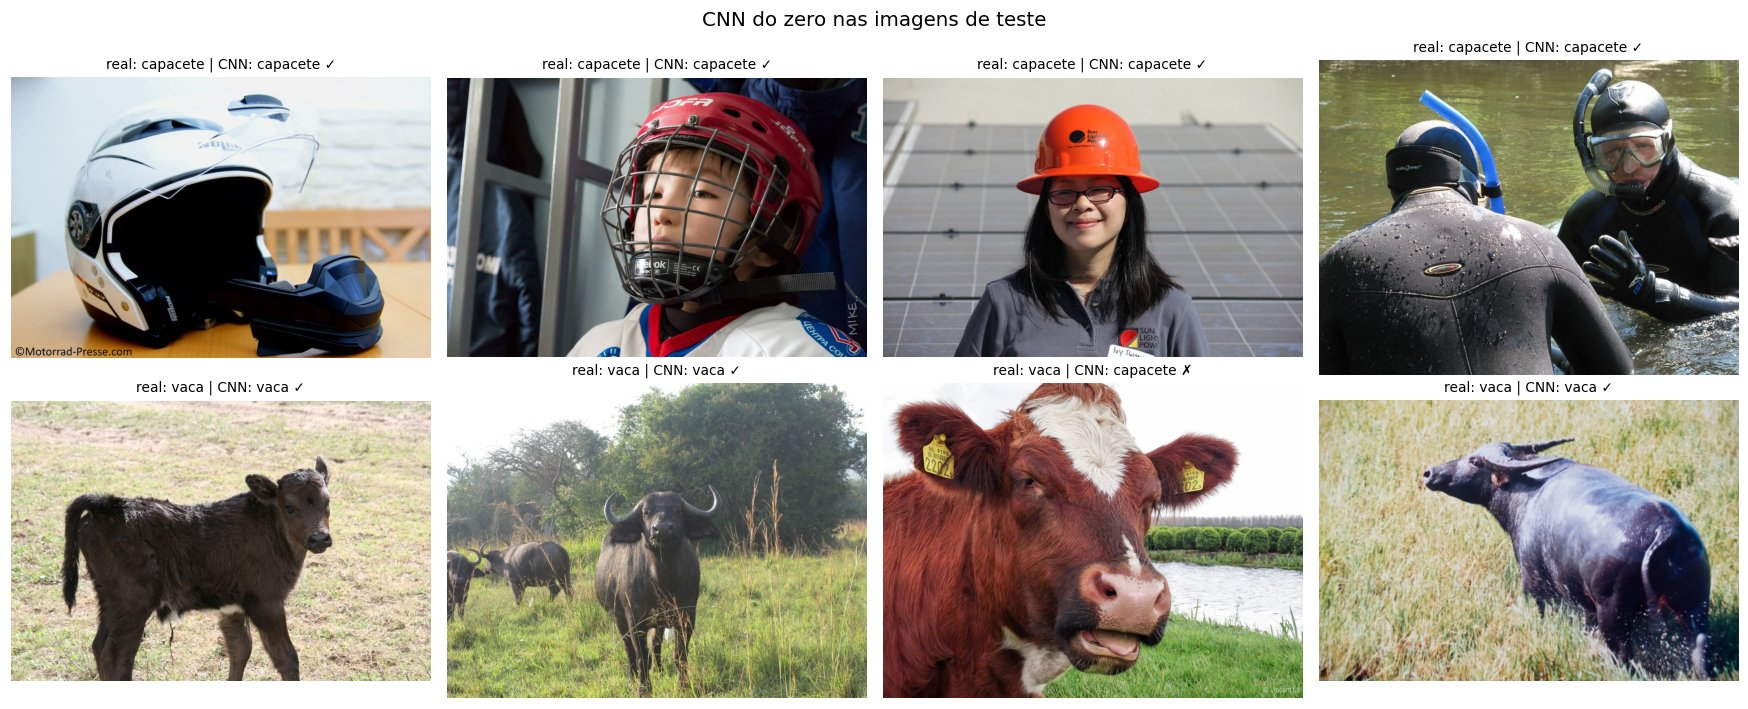

In [26]:
cnn.eval()


@torch.no_grad()
def prever_cnn(img):
    # Classe prevista pela CNN para uma imagem em disco
    x = tf_aval(Image.open(img).convert("RGB")).unsqueeze(0).to(DEV)
    return int(cnn(x).argmax(1))


y_pred_cnn, ms_cnn = medir(prever_cnn, imgs_teste)
registrar("CNN do zero", y_pred_cnn, ms_cnn, treino_cnn_s / 60)
print(f"Acurácia no teste: {np.mean(y_pred_cnn == y_teste):.3f} | {ms_cnn:.1f} ms por imagem")

# Matriz de confusão no teste (linhas = classe real, colunas = classe prevista)
display(
    pd.crosstab(
        pd.Categorical([CLASSES[c] for c in y_teste], CLASSES),
        pd.Categorical([CLASSES[c] for c in y_pred_cnn], CLASSES),
        rownames=["real"], colnames=["previsto"], dropna=False,
    )
)
mostrar_grade(
    imgs_teste,
    [f"real: {CLASSES[r]} | CNN: {CLASSES[p]} {'✓' if r == p else '✗'}" for r, p in zip(y_teste, y_pred_cnn)],
    titulo="CNN do zero nas imagens de teste",
)

## 12. Comparação das abordagens

Todas as abordagens medidas nas mesmas 8 imagens de teste, com o mesmo
procedimento. O mAP só existe para o YOLO customizado: a CNN não produz caixas, e
o YOLO padrão usa classes diferentes das nossas.

,acertos,acurácia (teste),sem detecção,mAP@0.5 (teste),treino (min),inferência (ms/img)
abordagem,,,,,,
YOLO customizado (30 ép.),8/8,1.000,0,0.902,2.7,28.1
YOLO customizado (60 ép.),8/8,1.000,0,0.946,3.8,22.6
YOLO padrão (COCO),4/8,0.500,4,—,0.0,22.0
CNN do zero,7/8,0.875,0,—,0.5,14.7


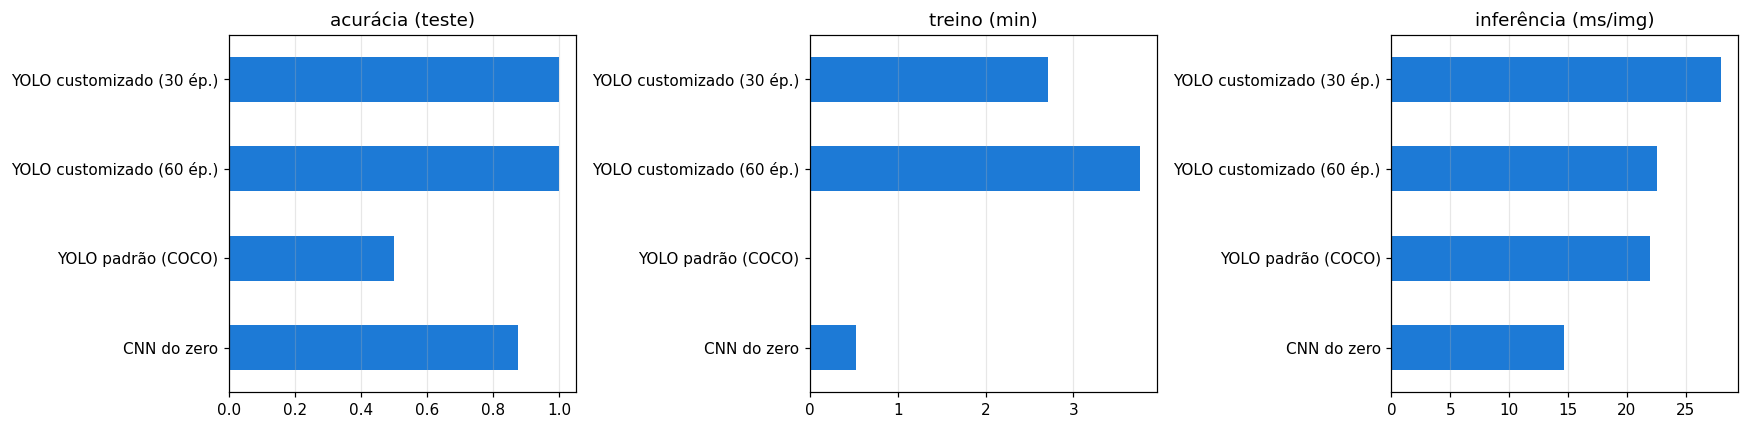

In [27]:
df_comp = pd.DataFrame(comparacao).set_index("abordagem")
display(df_comp.style.format({"acurácia (teste)": "{:.3f}", "mAP@0.5 (teste)": "{:.3f}", "treino (min)": "{:.1f}", "inferência (ms/img)": "{:.1f}"}, na_rep="—"))

# Acurácia, tempo de treino e tempo de inferência lado a lado
fig, eixos = plt.subplots(1, 3, figsize=(16, 4))
for ax, coluna in zip(eixos, ["acurácia (teste)", "treino (min)", "inferência (ms/img)"]):
    df_comp[coluna].plot.barh(ax=ax, color="#1d7ad6")
    ax.set_title(coluna)
    ax.set_ylabel("")
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
melhor_acc = df_comp["acurácia (teste)"].max()
lideres = " e ".join(df_comp.index[df_comp["acurácia (teste)"] == melhor_acc])
mais_rapida = df_comp["inferência (ms/img)"].idxmin()
sem_equiv = [c for c in CLASSES if not COCO_EQUIV.get(c)]
padrao, cnn_l = df_comp.loc["YOLO padrão (COCO)"], df_comp.loc["CNN do zero"]

# O resultado do YOLO padrão depende de as classes existirem no COCO
if sem_equiv:
    nota_padrao = (
        f"acertou {padrao['acertos']} imagens. A classe **{', '.join(sem_equiv)}** não existe no COCO, "
        "então essas imagens estão perdidas de saída: o teto deste modelo é limitado pelo vocabulário "
        "com que foi treinado, não pela qualidade da rede."
    )
else:
    nota_padrao = (
        f"acertou {padrao['acertos']} imagens sem nenhum treino, porque as duas classes existem no COCO."
    )

display(Markdown(f'''
### Resultados medidos

- **Precisão.** A maior acurácia no teste foi **{melhor_acc:.0%}**, obtida por: {lideres}.
- **YOLO padrão** {nota_padrao}
- **CNN do zero** acertou {cnn_l["acertos"]} imagens, com {treino_cnn_s:.0f} s de treino.
- **Inferência.** A abordagem mais rápida foi **{mais_rapida}**
  ({df_comp.loc[mais_rapida, "inferência (ms/img)"]:.1f} ms por imagem). Os modelos YOLO têm tempos
  parecidos entre si por compartilharem a mesma arquitetura.

Com 8 imagens de teste, cada imagem vale 12,5 pontos percentuais: diferenças de uma imagem entre
abordagens não são estatisticamente conclusivas.
'''))


### Resultados medidos

- **Precisão.** A maior acurácia no teste foi **100%**, obtida por: YOLO customizado (30 ép.) e YOLO customizado (60 ép.).
- **YOLO padrão** acertou 4/8 imagens. A classe **capacete** não existe no COCO, então essas imagens estão perdidas de saída: o teto deste modelo é limitado pelo vocabulário com que foi treinado, não pela qualidade da rede.
- **CNN do zero** acertou 7/8 imagens, com 31 s de treino.
- **Inferência.** A abordagem mais rápida foi **CNN do zero**
  (14.7 ms por imagem). Os modelos YOLO têm tempos
  parecidos entre si por compartilharem a mesma arquitetura.

Com 8 imagens de teste, cada imagem vale 12,5 pontos percentuais: diferenças de uma imagem entre
abordagens não são estatisticamente conclusivas.


### Avaliação crítica por critério

**Facilidade de uso e integração**

| Abordagem | Esforço | Comentário |
|-----------|---------|------------|
| YOLO padrão | Mínimo | Três linhas de código, sem dados nem treino. Só serve se o objeto estiver entre as 80 classes do COCO. |
| YOLO customizado | Médio | O código é pronto (`train.py`, `val.py`, `detect.py`); o trabalho está em **rotular caixas**, a etapa mais demorada de todo o projeto. |
| CNN do zero | Médio/alto | Rotulação trivial (só a classe), mas arquitetura, *augmentation*, laço de treino e escolha do melhor peso são todos responsabilidade nossa. |

**Precisão do modelo.** Os números medidos estão na tabela acima; o que se espera
de cada abordagem, e que ajuda a interpretá-los: o YOLO customizado combina
conhecimento geral herdado do COCO com especialização nas nossas classes. O YOLO
padrão é excelente dentro do seu vocabulário e inútil fora dele. A CNN do zero
precisa aprender tudo com 64 imagens, e por isso tende a se apoiar em atalhos —
cor predominante, tipo de fundo — que funcionam neste dataset mas podem falhar
fora dele; ela é a abordagem que mais se beneficiaria de mais dados.

**Tempo de treinamento.** O YOLO padrão não treina. A CNN treina em segundos por
ser pequena e trabalhar em baixa resolução. O YOLO customizado é o mais caro, por
ajustar milhões de parâmetros em imagens de 640×640 — ainda assim, minutos em GPU.

**Tempo de inferência.** A CNN é a mais leve: poucas camadas, imagem pequena e
uma única resposta. Os modelos YOLO fazem muito mais trabalho por imagem
(localizam vários objetos em várias escalas), mas continuam rápidos o bastante
para vídeo em tempo real numa GPU.

### Qual escolher?

Não há vencedora absoluta — depende da pergunta do cliente:

- **"Tem uma vaca nesta foto?"** com classes do COCO → **YOLO padrão**, pronto em minutos.
- **"Onde estão e quantos são os objetos X?"** com classes próprias → **YOLO customizado**;
  é a única das três que localiza e conta objetos que o COCO não conhece.
- **"Esta imagem é do tipo A ou B?"** com hardware limitado (por exemplo, embarcado) →
  uma **CNN pequena** pode bastar, desde que haja bem mais dados de treino.

### Limitações desta comparação

- A régua comum (classe da imagem) **favorece a CNN** ao ignorar a localização,
  que é justamente o diferencial do YOLO.
- O conjunto de teste tem apenas 8 imagens; os números são indicativos, não definitivos.
- Os tempos de inferência incluem a leitura do arquivo e variam com o hardware da
  sessão do Colab; servem para comparar ordens de grandeza, não milissegundos.
- A CNN foi avaliada em uma única arquitetura e uma única execução.

## 13. Salvando os resultados no Google Drive

Os pesos treinados (`best.pt`) e os gráficos gerados pelo YOLOv5 são copiados
para o Drive, ao lado do dataset, para não se perderem quando a sessão do Colab
terminar. O `best.pt` é o arquivo necessário para usar o modelo fora do notebook.

In [29]:
destino = DATASET.parent / "fase6_resultados"
for nome, sim in simulacoes.items():
    # Copia a pasta de cada treino (pesos, curvas, matrizes) e as imagens de teste processadas
    shutil.copytree(sim["pasta"], destino / nome, dirs_exist_ok=True)
    shutil.copytree(sim["detect"], destino / f"detect_{nome}", dirs_exist_ok=True)
print("Resultados salvos em", destino)

Resultados salvos em /content/drive/MyDrive/fase6_resultados
